# Arşiv — ilk keşif ve denemeler

Güncel eğitim ve değerlendirme `colab.ipynb`'de. Bu notebook'un çıktıları eski deney sonuçlarının
kaynağıdır (`src/deneyler_tasi.py` buradan okur); çıktıları silme.

In [1]:
import os, sys
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

# src/ paketini import edebilmek için repo kökünü path'e ekle
# (Colab'da önce: !git clone <repo-url> /content/child-drawing-analysis)
REPO = ".." if os.path.exists("../src") else "/content/child-drawing-analysis"
sys.path.insert(0, REPO)

from src.config import ORTAM, YOLLAR
from src.veri import KOK as kok, metadata_yukle, yukleyiciler
from src.bolme import stratifiye_bol
from src.egitim import egit, cihaz
print("Ortam:", ORTAM, "| cihaz:", cihaz)

# Veri seti yoksa tekrar indir
if not os.path.exists("kido/Dataset"):
    !pip install -q gdown
    !gdown 1Ip5HI3kqnZ0Lpc0jQKxl30IjHmksqkrf -O kido_dataset
    !unzip -q kido_dataset -d kido

df = metadata_yukle()
print(df.bolum.value_counts())

Mounted at /content/drive
Downloading...
From (original): https://drive.google.com/uc?id=1Ip5HI3kqnZ0Lpc0jQKxl30IjHmksqkrf
From (redirected): https://drive.google.com/uc?id=1Ip5HI3kqnZ0Lpc0jQKxl30IjHmksqkrf&confirm=t&uuid=8c5aaa27-266e-4b4a-b327-09d34d0b5506
To: /content/kido_dataset
100% 795M/795M [00:13<00:00, 59.5MB/s]
bolum
train    7842
test     1632
val      1386
Name: count, dtype: int64


In [ ]:
import os

kok = "kido/Dataset/Images"
for kategori in sorted(os.listdir(kok)):
    print(f"\n=== {kategori} ===")
    for alt in sorted(os.listdir(f"{kok}/{kategori}")):
        yol = f"{kok}/{kategori}/{alt}"
        if os.path.isdir(yol):
            dosyalar = sorted(os.listdir(yol))
            print(f"  {alt}: {len(dosyalar)} dosya | örnek: {dosyalar[:3]}")


=== Education ===
  test: 2 dosya | örnek: ['Primary', 'Secondary']
  train: 2 dosya | örnek: ['Primary', 'Secondary']

=== Emotion ===
  test: 2 dosya | örnek: ['Happiness', 'Sadness']
  train: 2 dosya | örnek: ['Happiness', 'Sadness']

=== Gender ===
  test: 2 dosya | örnek: ['Female', 'Male']
  train: 2 dosya | örnek: ['Female', 'Male']


In [ ]:
def dosya_adlari(kategori):
    adlar = set()
    for alt in os.listdir(f"{kok}/{kategori}"):
        yol = f"{kok}/{kategori}/{alt}"
        if os.path.isdir(yol):
            adlar.update(os.listdir(yol))
    return adlar

duygu, cinsiyet, egitim = dosya_adlari("Emotion"), dosya_adlari("Gender"), dosya_adlari("Education")
print("Emotion:", len(duygu), "| Gender:", len(cinsiyet), "| Education:", len(egitim))
print("Üçünde ortak dosya adı:", len(duygu & cinsiyet & egitim))

Emotion: 2 | Gender: 2 | Education: 2
Üçünde ortak dosya adı: 0


In [ ]:
def resimleri_topla(kategori):
    kayitlar = {}  # dosya_adi -> (split, etiket)
    for split in ["train", "test"]:
        for etiket in os.listdir(f"{kok}/{kategori}/{split}"):
            for dosya in os.listdir(f"{kok}/{kategori}/{split}/{etiket}"):
                kayitlar[dosya] = (split, etiket)
    return kayitlar

duygu = resimleri_topla("Emotion")
cinsiyet = resimleri_topla("Gender")
egitim = resimleri_topla("Education")

print("Resim sayıları -> Emotion:", len(duygu), "| Gender:", len(cinsiyet), "| Education:", len(egitim))
ortak = set(duygu) & set(cinsiyet) & set(egitim)
print("Üçünde ortak dosya adı:", len(ortak))
print("Örnek dosya adları:", list(duygu)[:5])


Resim sayıları -> Emotion: 10860 | Gender: 10860 | Education: 10860
Üçünde ortak dosya adı: 10860
Örnek dosya adları: ['101-1C-535-M-H.jpg', '104-4B-377-M-H.jpg', '250-6L-60-M-H.jpg', '101-4E-140-M-H.jpg', '280-5N-2298-F-H.jpg']


In [ ]:
ayni_split = sum(1 for d in ortak if duygu[d][0] == cinsiyet[d][0] == egitim[d][0])
print(f"Ortak resimlerin {ayni_split} / {len(ortak)} tanesi üç klasörde de aynı split'te")

Ortak resimlerin 10860 / 10860 tanesi üç klasörde de aynı split'te


In [ ]:
import pandas as pd

satirlar = []
for dosya in duygu:
    parca = dosya.replace(".jpg", "").split("-")
    satirlar.append({
        "dosya": dosya,
        "split": duygu[dosya][0],
        "duygu": duygu[dosya][1],
        "cinsiyet": cinsiyet[dosya][1],
        "egitim": egitim[dosya][1],
        "ogrenci": "-".join(parca[:3]),  # okul-sınıf-no
        "ad_cinsiyet": parca[3],
        "ad_duygu": parca[4],
    })
df = pd.DataFrame(satirlar)

# Dosya adındaki harfler klasör etiketleriyle tutarlı mı?
print("Cinsiyet tutarlı:", (df.ad_cinsiyet == df.cinsiyet.str[0]).mean())
print("Duygu tutarlı:", (df.ad_duygu == df.duygu.str[0]).mean())

# Öğrenci başına çizim sayısı ve split sızıntısı
print("\nÖğrenci başına çizim sayısı:", df.groupby("ogrenci").size().value_counts().to_dict())
karisik = df.groupby("ogrenci").split.nunique()
print("Hem train hem test'te çizimi olan öğrenci:", (karisik > 1).sum())

df.head()


Cinsiyet tutarlı: 1.0
Duygu tutarlı: 1.0

Öğrenci başına çizim sayısı: {2: 5430}
Hem train hem test'te çizimi olan öğrenci: 0


,dosya,split,duygu,cinsiyet,egitim,ogrenci,ad_cinsiyet,ad_duygu
0,101-1C-535-M-H.jpg,train,Happiness,Male,Primary,101-1C-535,M,H
1,104-4B-377-M-H.jpg,train,Happiness,Male,Primary,104-4B-377,M,H
2,250-6L-60-M-H.jpg,train,Happiness,Male,Secondary,250-6L-60,M,H
3,101-4E-140-M-H.jpg,train,Happiness,Male,Primary,101-4E-140,M,H
4,280-5N-2298-F-H.jpg,train,Happiness,Female,Secondary,280-5N-2298,F,H


In [ ]:
print("Cinsiyet tutarlı:", (df.ad_cinsiyet == df.cinsiyet.str[0]).mean())
print("Duygu tutarlı:", (df.ad_duygu == df.duygu.str[0]).mean())
print("Öğrenci başına çizim sayısı:", df.groupby("ogrenci").size().value_counts().to_dict())
print("Hem train hem test'te çizimi olan öğrenci:", (df.groupby("ogrenci").split.nunique() > 1).sum())

Cinsiyet tutarlı: 1.0
Duygu tutarlı: 1.0
Öğrenci başına çizim sayısı: {2: 5430}
Hem train hem test'te çizimi olan öğrenci: 0


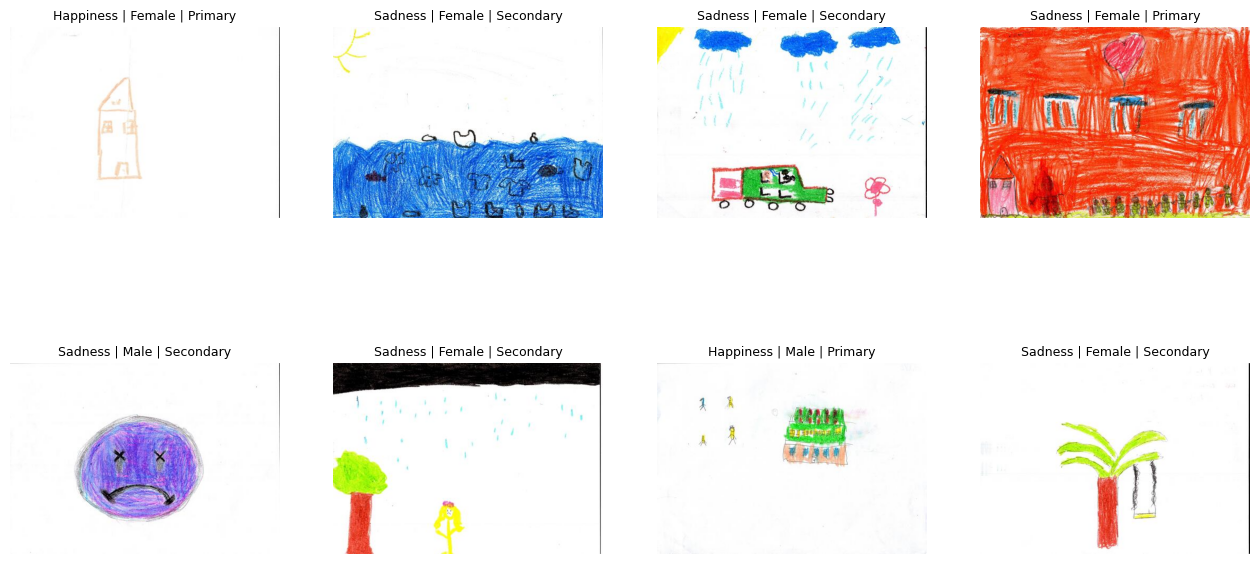

(512, 362)    299
(512, 365)      1
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def resim_yolu(satir):
    return f"{kok}/Emotion/{satir.split}/{satir.duygu}/{satir.dosya}"

ornekler = df.sample(8, random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, s) in zip(axes.flat, ornekler.iterrows()):
    ax.imshow(Image.open(resim_yolu(s)))
    ax.set_title(f"{s.duygu} | {s.cinsiyet} | {s.egitim}", fontsize=9)
    ax.axis("off")
plt.show()

boyutlar = [Image.open(resim_yolu(s)).size for _, s in df.sample(300, random_state=0).iterrows()]
print(pd.Series(boyutlar).value_counts().head(10))

In [ ]:
print(pd.crosstab(df.split, df.duygu, margins=True), "\n")
print(pd.crosstab([df.split, df.egitim], [df.cinsiyet, df.duygu]))

duygu  Happiness  Sadness    All
split                           
test         816      816   1632
train       4614     4614   9228
All         5430     5430  10860 

cinsiyet           Female              Male        
duygu           Happiness Sadness Happiness Sadness
split egitim                                       
test  Primary         221     221       187     187
      Secondary       271     271       137     137
train Primary        1260    1260      1047    1047
      Secondary      1467    1467       840     840


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

os.makedirs(os.path.dirname(YOLLAR["metadata"]), exist_ok=True)
df.drop(columns=["ad_cinsiyet", "ad_duygu"]).to_csv(YOLLAR["metadata"], index=False)
print("Kaydedildi.")

Mounted at /content/drive
Kaydedildi.


In [ ]:
df = stratifiye_bol(df, test_size=0.15, random_state=42)
print(pd.crosstab([df.bolum, df.egitim], [df.cinsiyet, df.duygu]))

df.drop(columns=["ad_cinsiyet", "ad_duygu"]).to_csv(YOLLAR["metadata"], index=False)

cinsiyet           Female              Male        
duygu           Happiness Sadness Happiness Sadness
bolum egitim                                       
test  Primary         221     221       187     187
      Secondary       271     271       137     137
train Primary        1071    1071       890     890
      Secondary      1246    1246       714     714
val   Primary         189     189       157     157
      Secondary       221     221       126     126


In [ ]:
train_dl, val_dl = yukleyiciler(df, boyut=224)

x, y = next(iter(train_dl))
print(x.shape, y[:10])

torch.Size([32, 3, 224, 224]) tensor([1, 1, 1, 1, 0, 1, 1, 1, 0, 0])


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.metrics import f1_score

torch.manual_seed(42)
cihaz = "cuda"
model = resnet50(weights=ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(cihaz)

optim = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
kayip_fn = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda")
EPOCH, en_iyi_f1 = 10, 0

for epoch in range(EPOCH):
    model.train(); toplam = 0
    for x, y in train_dl:
        x, y = x.to(cihaz), y.to(cihaz)
        optim.zero_grad()
        with torch.autocast("cuda", dtype=torch.float16):
            kayip = kayip_fn(model(x), y)
        scaler.scale(kayip).backward()
        scaler.step(optim); scaler.update()
        toplam += kayip.item() * len(y)

    model.eval(); tahmin, gercek = [], []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for x, y in val_dl:
            tahmin += model(x.to(cihaz)).argmax(1).cpu().tolist()
            gercek += y.tolist()
    f1 = f1_score(gercek, tahmin, average="macro")
    acc = sum(t == g for t, g in zip(tahmin, gercek)) / len(gercek)
    print(f"Epoch {epoch+1}: train kayıp {toplam/len(train_dl.dataset):.4f} | val acc {acc:.4f} | val F1 {f1:.4f}")

    if f1 > en_iyi_f1:
        en_iyi_f1 = f1
        torch.save(model.state_dict(), f"{YOLLAR['cikti']}/resnet50_en_iyi.pt")
        print("  -> en iyi model kaydedildi")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


Epoch 1: train kayıp 0.5844 | val acc 0.7258 | val F1 0.7256
  -> en iyi model kaydedildi
Epoch 2: train kayıp 0.4739 | val acc 0.7367 | val F1 0.7366
  -> en iyi model kaydedildi
Epoch 3: train kayıp 0.3853 | val acc 0.7237 | val F1 0.7191
Epoch 4: train kayıp 0.3071 | val acc 0.7431 | val F1 0.7431
  -> en iyi model kaydedildi
Epoch 5: train kayıp 0.2381 | val acc 0.7518 | val F1 0.7517
  -> en iyi model kaydedildi
Epoch 6: train kayıp 0.1856 | val acc 0.7287 | val F1 0.7270
Epoch 7: train kayıp 0.1473 | val acc 0.7403 | val F1 0.7402
Epoch 8: train kayıp 0.1098 | val acc 0.7237 | val F1 0.7211
Epoch 9: train kayıp 0.0949 | val acc 0.7367 | val F1 0.7356
Epoch 10: train kayıp 0.0875 | val acc 0.7266 | val F1 0.7262


In [2]:
CIKTI = YOLLAR["cikti"]

In [ ]:
egit(df, "resnet50", boyut=224, cikti=CIKTI)
egit(df, "resnet50", boyut=320, cikti=CIKTI)

Epoch 1: val F1 0.7242
Epoch 2: val F1 0.7323
Epoch 3: val F1 0.7372
Epoch 4: val F1 0.7410
Epoch 5: val F1 0.7292
Epoch 6: val F1 0.7452
Epoch 7: val F1 0.7489
Epoch 8: val F1 0.7388
Sonuç: {'deney': 'resnet50_224px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.7489, 'epoch': 7, 'dakika': 7.4}
Epoch 1: val F1 0.7331
Epoch 2: val F1 0.7504
Epoch 3: val F1 0.7576
Epoch 4: val F1 0.7756
Epoch 5: val F1 0.7657
Epoch 6: val F1 0.7716
Epoch 7: val F1 0.7791
Epoch 8: val F1 0.7777
Sonuç: {'deney': 'resnet50_320px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.7791, 'epoch': 7, 'dakika': 11.0}


In [22]:
egit(df, "resnet50", boyut=448, cikti=CIKTI)
egit(df, "efficientnet_b0", boyut=320, lr=3e-4, cikti=CIKTI)
egit(df, "convnext_tiny", boyut=320, cikti=CIKTI)

Epoch 1: val F1 0.7345
Epoch 2: val F1 0.7860
Epoch 3: val F1 0.7551
Epoch 4: val F1 0.7828
Epoch 5: val F1 0.7818
Epoch 6: val F1 0.7985
Epoch 7: val F1 0.7893
Epoch 8: val F1 0.7899
Sonuç: {'deney': 'resnet50_448px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.7985, 'epoch': 6, 'dakika': 20.4}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 210MB/s]


Epoch 1: val F1 0.7150
Epoch 2: val F1 0.7388
Epoch 3: val F1 0.7112
Epoch 4: val F1 0.7431
Epoch 5: val F1 0.7266
Epoch 6: val F1 0.7337
Epoch 7: val F1 0.7323
Epoch 8: val F1 0.7395
Sonuç: {'deney': 'efficientnet_b0_320px_lr0.0003_ls0.1_s42', 'en_iyi_val_f1': 0.7431, 'epoch': 4, 'dakika': 10.1}
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 197MB/s]
/tmp/ipykernel_498/2182643763.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(kayip).backward(); scaler.step(optim); scaler.update(); plan.step()


Epoch 1: val F1 0.7734
Epoch 2: val F1 0.7950
Epoch 3: val F1 0.7862
Epoch 4: val F1 0.8081
Epoch 5: val F1 0.8051
Epoch 6: val F1 0.8088
Epoch 7: val F1 0.8102
Epoch 8: val F1 0.8110
Sonuç: {'deney': 'convnext_tiny_320px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.811, 'epoch': 8, 'dakika': 12.8}


In [8]:
egit(df, "convnext_tiny", boyut=320, epoch=12, cikti=CIKTI)
egit(df, "convnext_tiny", boyut=448, cikti=CIKTI)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 177MB/s]
/tmp/ipykernel_615/2182643763.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(kayip).backward(); scaler.step(optim); scaler.update(); plan.step()


Epoch 1: val F1 0.7741
Epoch 2: val F1 0.7994
Epoch 3: val F1 0.8066
Epoch 4: val F1 0.8040
Epoch 5: val F1 0.7819
Epoch 6: val F1 0.7980
Epoch 7: val F1 0.8019
Epoch 8: val F1 0.8036
Epoch 9: val F1 0.8044
Epoch 10: val F1 0.8066
Epoch 11: val F1 0.8095
Epoch 12: val F1 0.8066
Sonuç: {'deney': 'convnext_tiny_320px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.8095, 'epoch': 11, 'dakika': 19.6}
Epoch 1: val F1 0.7763
Epoch 2: val F1 0.8075
Epoch 3: val F1 0.8160
Epoch 4: val F1 0.8167
Epoch 5: val F1 0.8282
Epoch 6: val F1 0.8189
Epoch 7: val F1 0.8203
Epoch 8: val F1 0.8196
Sonuç: {'deney': 'convnext_tiny_448px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.8282, 'epoch': 5, 'dakika': 23.4}


In [ ]:
egit(df, "convnext_tiny", boyut=320, epoch=12, cikti=CIKTI)
egit(df, "convnext_tiny", boyut=448, cikti=CIKTI)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 206MB/s]
/tmp/ipykernel_1437/2182643763.py:40: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(kayip).backward(); scaler.step(optim); scaler.update(); plan.step()


Epoch 1: val F1 0.7741
Epoch 2: val F1 0.7994
Epoch 3: val F1 0.8066
Epoch 4: val F1 0.8040
Epoch 5: val F1 0.7819
Epoch 6: val F1 0.7980
Epoch 7: val F1 0.8019
Epoch 8: val F1 0.8036
Epoch 9: val F1 0.8044
Epoch 10: val F1 0.8066
Epoch 11: val F1 0.8095
Epoch 12: val F1 0.8066
Sonuç: {'deney': 'convnext_tiny_320px_lr0.0001_ls0.1_s42', 'en_iyi_val_f1': 0.8095, 'epoch': 11, 'dakika': 19.1}
